# Demo - using fitting pipeline

This demo notebook shows how to apply the fitting pipeline to fit clonal dynamics with a tissue model. 

A 0D SD model is used for this example, with small cell numbers to reduce runtime. The dataset used is combined male mice, but other datasets from "experiment" can be selected.

Increasing the cell numbers, and the granularity/number of parameters sweeped over will improve the fitting quality.

In [15]:
#Imports
import numpy as np
import matplotlib.pyplot as plt
import sys

sys.path.append("../fit/")
sys.path.append("../sim/")
sys.path.append("../plot/")


from tissue import *
import tissplot as tplt
import matplotlib.path as mplPath
import datasets as ds 
import tiss_optimize as topt
import sim_model
import custom_metrics as cmet


# Specify model
model = sim_model.SD_0D

# Select folder to save results
savefolder = 'ctr_SD0D/'

# Specify number of cores for parallilisation
ncores = 5
ncells = 500 #Using a small number of cells for the demo
tsteps = -50 #negative numbers specify the number of division times to simulate
# This determines the maximum division rate

# Specify dataset from list of datasets
dataset = ['data_ctr_M.pkl',    'data_ctr_F.pkl', 
                'data_castre.pkl', 'data_Ovx.pkl', 
                'data_Lgr6_M.pkl', 'data_Lgr6_F.pkl',
                'data_Notch1_M.pkl', 'data_Notch1_F.pkl']

didx = 0


if didx < 2:
    exp_file = '../experiment/homeo/' + dataset[didx]
elif didx == 2:
    exp_file = '../experiment/castre/' + dataset[didx]
elif didx == 3:
    exp_file = '../experiment/ovx/' + dataset[didx]    
elif didx  < 6:
    exp_file = '../experiment/lgr6/' + dataset[didx]    
elif didx < 8:
    exp_file = '../experiment/notch/' + dataset[didx]    
else:
    assert(0)


#Specify metrics for use in analysis
ksdists  = {'dist': ['S2like.basalCS', 'S2like.supraCS'], 'dist_metric': 'ksd', 'name': 'ksd_b_sb'}
k1dists  = {'dist': ['S2like.basalCS'], 'dist_metric': 'ksd', 'name': 'ksd_bas'}
full = {'custom_metrics': {'S2like.fulljointCS': cmet.logLL_joint, 'Dlike.fulljointCS': cmet.logLL_joint}, 'name': 'full', 
        'exclude_times': {'S2like.fulljointCS': np.arange(6,7)}}

mets = [full, ksdists, k1dists]  

compute_kwargs = {'Dlike': {'containsBasal': False}}
toCalculate = ['Dlike.basalCS', 'Dlike.supraCS', 'S2like.basalCS', 'S2like.supraCS', 
               'basalCS', 'supraCS', 'S2like.lcd', 'Dlike.lcd', 'S2like.pers', 'Dlike.pers',
               'S2like.fulltotalCS', 'Dlike.fulltotalCS', 'S2like.fullsupraCS',
               'Dlike.fullsupraCS']
    
# Specify rho (SC density)
# This is typically used based on mean-field values (see Supplementary Note)
# However, you ca
if '_M' in exp_file:
    rho = 0.6
elif '_F' in exp_file:
    rho = 0.4
else:
    print('rho not provided')
    assert(0)

#Set-up optimiser - allows simulated annealing or gridsearch
useSA = False # Whether to use SA
i = -1 # Positive values run a particular index

# Mark free params for gridsearch or SA
freeParams = {'r':   np.arange(0.1, 0.5, 0.1), 
                'corrSD': [0.0, 1.0], 
                'corrDD': [0.0, 0.75]}

# Mark fixed params
fixedParams = {'tau': 100.0, 'rho': rho, 'CVd_S': 0.5, 'CVd_D': 1.0, 'corrSS': 0.0}
# Note division rate (1/tscale), will be fitted automatically by rescaling time
s0 = topt.sim_anneal(model, freeParams, params = fixedParams, simtype = 'h',
                exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                compute_kwargs = compute_kwargs, toCalculate = toCalculate,
            move_seed = np.abs(i),  use_linear = ['r', 'rho', 'CVd_S', 'CVd_D', 'corrSD', 'corrDD', 'corrSS'],
            move_sizes =     {'r': 0.05, 'rho':  0.025, 'CVd_S':  0.1, 'CVd_D':  0.1, 'corrSD':  0.1, 'corrDD':  0.1, 'corrSS':  0.1},
            free_param_min = {'r': 0.00, 'rho':   0.1,  'CVd_S':  0.0, 'CVd_D':  0.0, 'corrSD':  0.0, 'corrDD':  0.0, 'corrSS':  0.0},
            free_param_max = {'r': 1.00, 'rho':   1.0,  'CVd_S': 1.05, 'CVd_D': 1.05, 'corrSD': 1.05, 'corrDD': 1.05, 'corrSS': 1.05})




# post-optimisation over the cv of suprbasal shed time, using a grid search by rerunning the supbsal layer
postopt = {'sbas_cv': np.arange(0.1, 1.01, 0.5)}


# Run optimisation or simulated annealing
if not useSA:
    if i > -1000:
        s0.optimise(ncells = ncells, tsteps = tsteps, seeds = np.arange(1), savefolder = savefolder,
            #Sets range of value for tscale and shed for fitting
            tscalevals = -np.arange(2,14,0.05), shedvals = -np.arange(0.2, 2.0, 0.1), 
            #Performs a search over the 
            postopt_params = postopt, 
            use_saved_metrics = False, ncores = ncores, save_every = 5, merge_during = i < 0,
            mergefirst = False, init_params = {'relaxsteps': 0, 'homeosteps': 1000}, sim_args = {},
            skip = 5, save_sweeps = False, par_seed = False, i = i*(i > 0) + -1*(i < 0), nboots = 0, save_to_runspace = False,
            postopt_settings = {'tscale_by_quantity': 'S2like.basalCS', 'tscale_inc_times': np.arange(2,6)})
    elif i == -1000:
        s0.merge_indexed_searchspace(np.arange(22000), ncells = ncells, tsteps = tsteps, savefolder = savefolder)
else:
    if i >= -1000:
        s0.runSA(ncells = ncells, tsteps = tsteps, seeds = np.arange(1), savefolder = savefolder,
                    tscalevals = -np.arange(2,14,0.05), shedvals = -np.arange(0.2, 2.0, 0.1), 
                    postopt_params = {'sbas_cv': np.arange(0.1, 1.01, 0.1)}, merge_during = True,
                    use_saved_metrics = True, ncores = ncores, save_every = 1, mergefirst = True,
                    init_params = {'relaxsteps': 0, 'homeosteps': 1000}, sim_args = {'p0': 3.5, 'dt': 1e-2},
                    SAsteps = 100, T0 = 10, start_idx = -1, skip = 5, save_sweeps = False,
                    postopt_settings = {'tscale_by_quantity': 'S2like.basalCS', 'tscale_inc_times': np.arange(2,6)})

    elif i < -1000:
        s0.merge_seeded_searchspace(move_seeds = np.arange(200), ncells = ncells, tsteps = tsteps, savefolder = savefolder)    


Running with sims in parallel with ncores = 5
Running for: {'CVd_D': np.float64(1.0), 'CVd_S': np.float64(0.5), 'corrDD': np.float64(0.0), 'corrSD': np.float64(1.0), 'corrSS': np.float64(0.0), 'r': np.float64(0.2), 'rho': np.float64(0.6), 'tau': np.float64(100.0)}
Running for: {'CVd_D': np.float64(1.0), 'CVd_S': np.float64(0.5), 'corrDD': np.float64(0.0), 'corrSD': np.float64(0.0), 'corrSS': np.float64(0.0), 'r': np.float64(0.2), 'rho': np.float64(0.6), 'tau': np.float64(100.0)}
Running for: {'CVd_D': np.float64(1.0), 'CVd_S': np.float64(0.5), 'corrDD': np.float64(0.0), 'corrSD': np.float64(1.0), 'corrSS': np.float64(0.0), 'r': np.float64(0.1), 'rho': np.float64(0.6), 'tau': np.float64(100.0)}
τ range: 2.76 to 140.0
τ range: 2.76 to 140.0
τ range: 2.76 to 140.0
Running for: {'CVd_D': np.float64(1.0), 'CVd_S': np.float64(0.5), 'corrDD': np.float64(0.0), 'corrSD': np.float64(0.0), 'corrSS': np.float64(0.0), 'r': np.float64(0.1), 'rho': np.float64(0.6), 'tau': np.float64(100.0)}
τ range: 

tscale: -5.1
τ range: 2.76 to 140.0
shed: -0.9 refract: 0.0 cv: 0.6
Already cropped
Already cropped


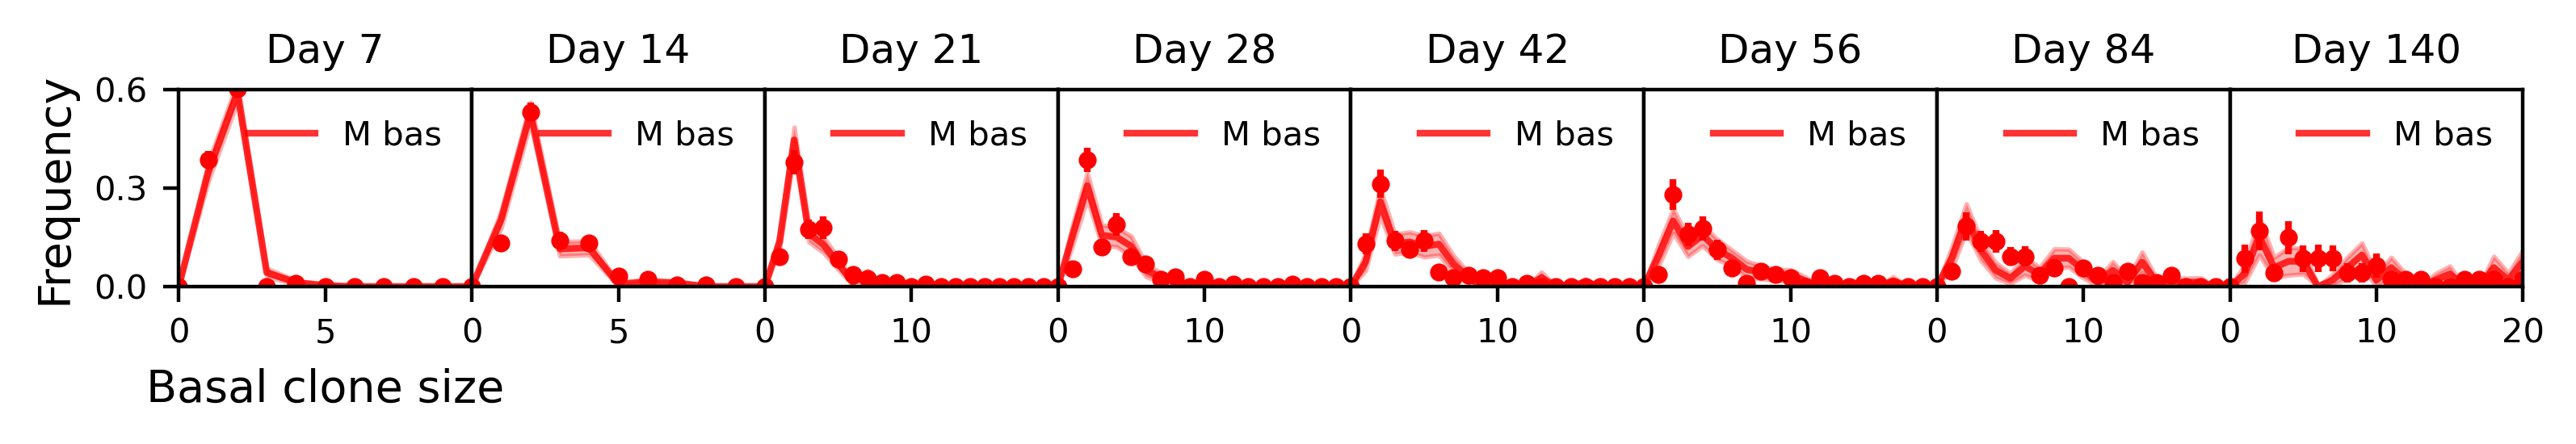

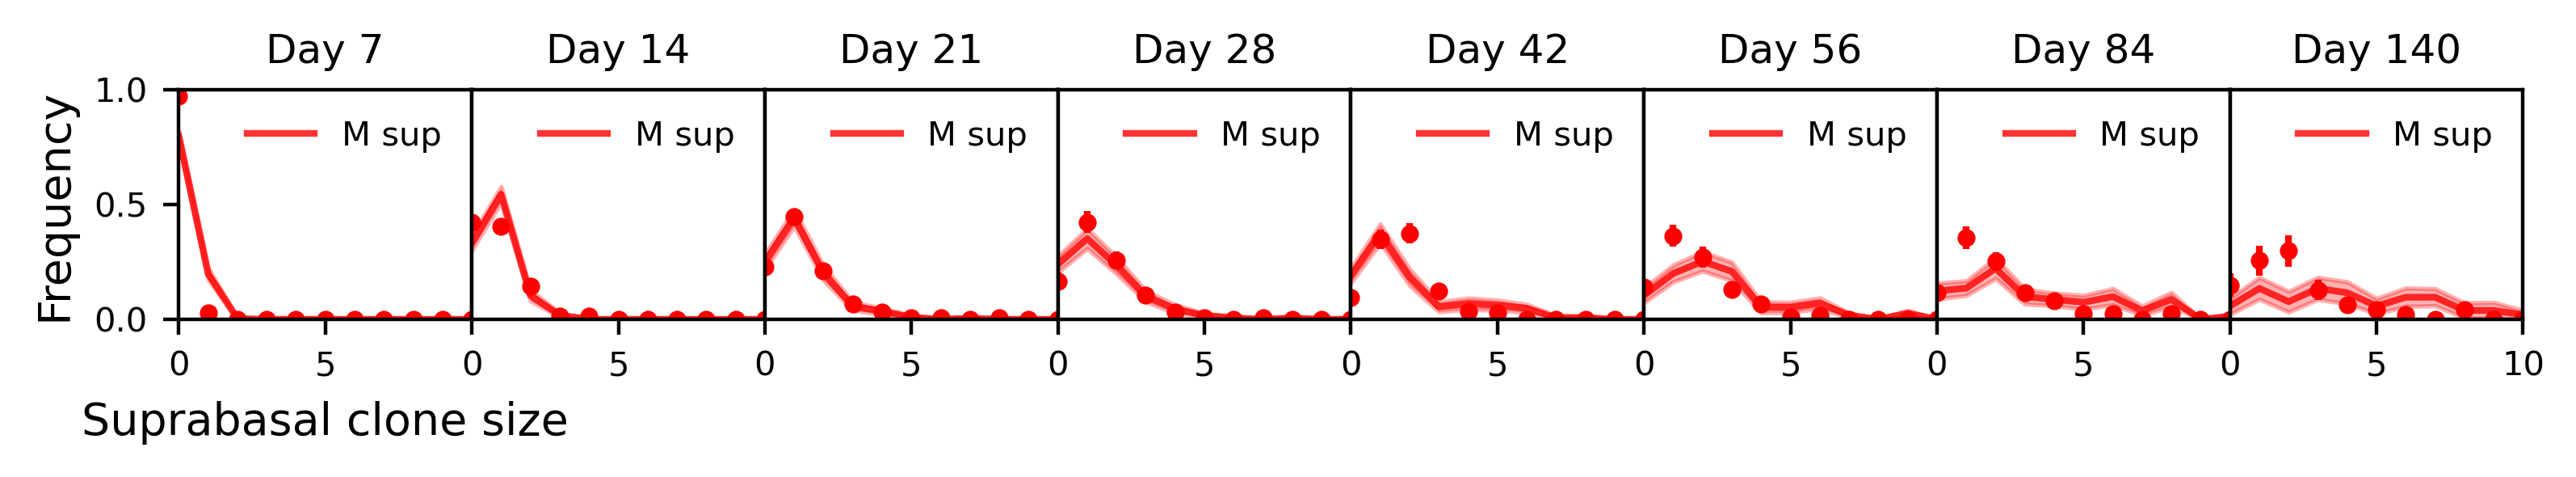

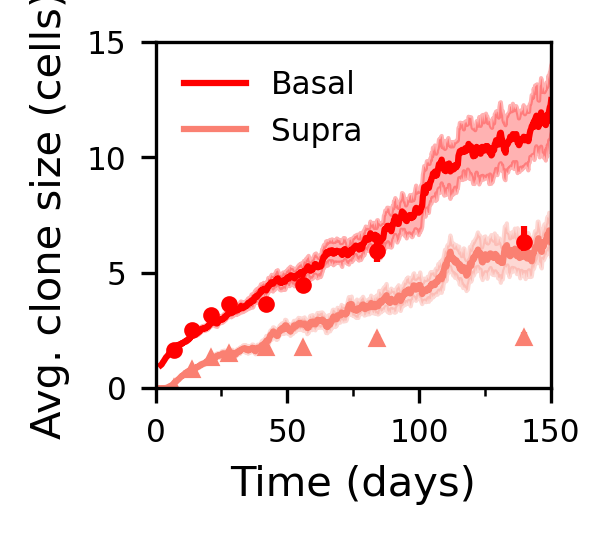

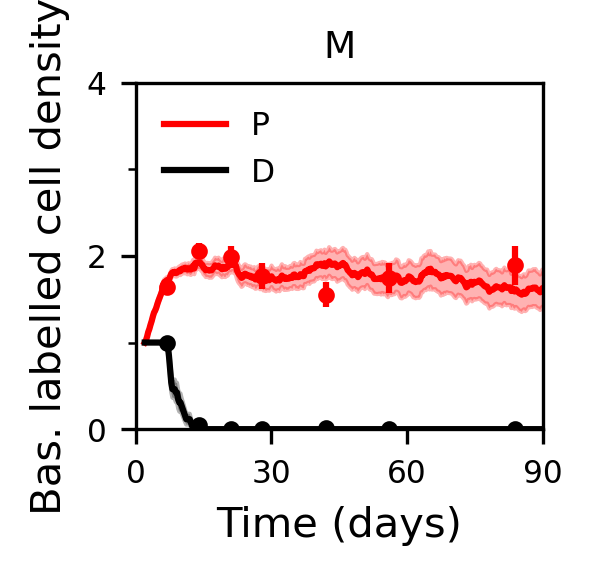

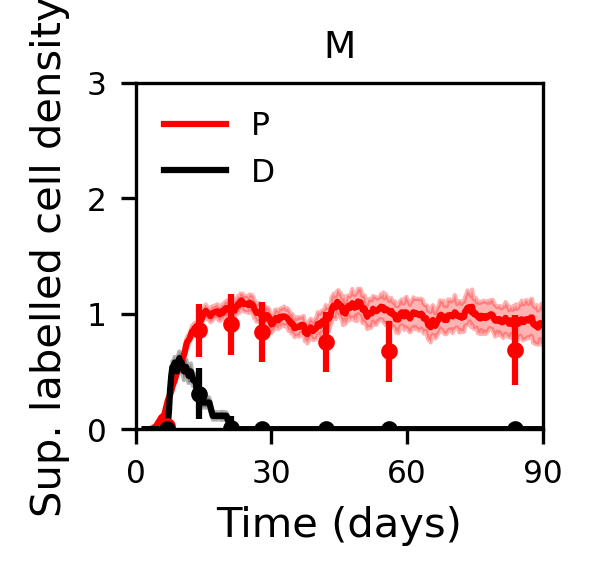

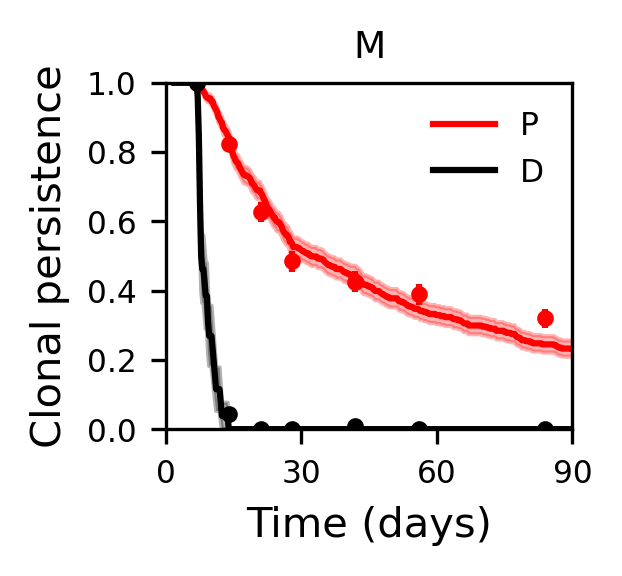

In [20]:
# Plot fits
from matplotlib import rcParams
# Set global font size for all axes
rcParams['axes.labelsize'] = 10
rcParams['axes.labelweight'] = 'normal'
rcParams['xtick.labelsize'] = 7.5
rcParams['ytick.labelsize'] = 7.5
rcParams['legend.fontsize'] = 7.5
rcParams['font.size'] = 7.5  # General font size
rcParams['text.usetex'] = False
rcParams['svg.fonttype'] = 'none'
rcParams['lines.markersize']  = 3
rcParams['lines.linewidth']  = 1.5


# Names and cols for plotting
sex = 'M'
sexname = {'M': 'M', 'F': 'F', 'castre': 'cM'}
cols = {'M': 'r', 'F': 'b', 'castre': 'purple'}
sec_cols = {'M': 'salmon', 'F': 'deepskyblue', 'castre': 'violet'}

# Specify metric
met = 'full'

# Load best fit
sim_data = s0.get_best_fit(met, tsteps, ncells, savefolder = savefolder, 
                            nseeds = 1, save_results = True, skip = 5, 
                            print_fit = False, init_params = {'relaxsteps': 0, 
                                                                'homeosteps': 1000},
                                                                norun = True)

exp_data = s0.exp_data


# Crop data to experimental times
sdt = sim_data.data_time_crop()
axs = ds.plot_dist('S2like.basalCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = False, xlabel= 'Basal clone size', prelabel= f'{sexname[sex]} bas', bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.0, ymax = 0.6, xmax = [10, 10, 20, 20,20,20,20,20],
                ylabel = 'Frequency', nolegend = False, yscale = 1.4, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6])
axs = ds.plot_dist('S2like.supraCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = False, 
            xlabel= 'Suprabasal clone size', prelabel= f'{sexname[sex]} sup', bootSEs=True, color = f'{cols[sex]}', 
                ncols=8, im_width = 1.0, ymax = 1.0, xmax = [10, 10, 10, 10,10,10,10,10],
                ylabel = 'Frequency', nolegend = False, yscale = 1.5, num_xticks = 3, nogaps = True, 
                yticks = [0,0.5,1.0])



plt.figure(figsize = (1.7,1.5), dpi = 300)  
ds.plot_quantity('S2like.basalCS', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'Basal', color = cols[sex], xfmt = 'o', sfmt = '-')
ds.plot_quantity('S2like.supraCS', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'Avg. clone size (cells)', plot_seeded = False, bootSEs = True, prelabel = 'Supra', color = sec_cols[sex], xfmt = '^', sfmt = '-')
plt.xlim([0,150])
plt.ylim([0,15])
plt.yticks(np.arange(0, 16, 5))
#plt.yticks(np.arange(0, 13, 2), minor = True)
plt.xticks(np.arange(0, 151, 50))
plt.xticks(np.arange(0, 151, 25), minor = True)
plt.legend(frameon = False)
plt.show() 


plt.figure(figsize = (1.75,1.5), dpi = 300)
ds.plot_quantity('S2like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'P', color = cols[sex])
ds.plot_quantity('Dlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'Bas. labelled cell density', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
#plt.title(dataset[didx])
plt.xlim([0,30])
plt.ylim([0,4])
plt.yticks(np.arange(0, 4, 1),minor = True)
plt.yticks([0,2,4])            
plt.xticks(np.arange(0, 91, 30))
plt.legend(frameon = False, loc = 'upper left')
plt.title(sex)
plt.show() 

plt.figure(figsize = (1.75,1.5), dpi = 300)
ds.plot_quantity('S2like.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'P', color = cols[sex])
ds.plot_quantity('Dlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'Sup. labelled cell density', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
#plt.title(dataset[didx])
plt.xlim([0,30])
plt.ylim([0,3])
plt.xticks(np.arange(0, 91, 30))
plt.legend(frameon = False, loc = 'upper left')
plt.title(sex)
plt.show()             

plt.figure(figsize = (1.75,1.5), dpi = 300)
ds.plot_quantity('S2like.pers', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'Persistence', plot_seeded = False, bootSEs = True, prelabel = 'P', color = cols[sex])
ds.plot_quantity('Dlike.pers', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'Clonal persistence', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
plt.xlim([0,90])
plt.ylim([0,1])
plt.xticks(np.arange(0, 91, 30))
plt.legend(frameon = False)
plt.title(sex)
plt.show() 


